## Wczytanie i transformacja zbioru

In [16]:
%load_ext autoreload
%autoreload 2

import sys
import os
sys.path.append(os.path.abspath('..'))
import pandas as pd
import numpy as np
from src.loader import load_data
from src.preprocess import map_class, get_subject_split
from src.features import build_dataset
from src.models import run_grid_search, get_pipeline
from src.visualizations import plot_confusion_matrix, plot_roc, plot_importance
from sklearn.metrics import classification_report

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Wczytujemy dane, od razu przekształcamy wszystkie na nasze nowe cechy z częstotliwosciami.
Nie dojdzie tu do wycieku danych, bo nasze transformacje są wyliczane tylko na dwusekundowym
oknie dla jednego, konkretnego pacjenta, a jak wiemy, dane pacjenta nie będą przemieszane pomiędzy zbiorem treningowym a testowym. Dopiero po tym dzielimy zbiór, wyrzucamy też metadane jak ID i numer okna czasowego.

In [2]:
data_raw = load_data("../data/adhdata.csv")
data_mapped = map_class(data_raw)
df_features = build_dataset(data_mapped)

In [3]:
X_train, X_test, y_train, y_test = get_subject_split(df_features, target_col='Class', group_col='ID')

X_train = X_train.drop(columns=['ID', 'window'])
X_test = X_test.drop(columns=['ID', 'window'])

print(f"Rozmiar zbioru treningowego: {X_train.shape}")
print(f"Rozmiar zbioru testowego: {X_test.shape}")

Rozmiar zbioru treningowego: (6725, 96)
Rozmiar zbioru testowego: (1675, 96)


## Testowanie modeli

Jesli chodzi, o metrykę, która wydaje się ważniejsza, jest nią Recall (inaczej True Positive Rate), który pokazuje, jaką wykrylismy częsć przypadków pozytywnych - tak jak we wszystkich testach medycznych, wolimy się pomylić, wskazać że zdrowa osoba jest chora i wydać pieniądze na dodatkowe badania, niż ominąć chorą osobę. Mimo tego, w GridSearchu, jeśli ustawimy ocenianie modelu po Recallu, prowadzi to od trywialnych rozwiązań, w których model daje każdemu klasę 1, ale ma precyzję równą 0. Będziemy więc oceniać modele po polu pod krzywą ROC, która intuicyjnie dla każdego progu odcięcia pokazuje trade - off między false positive rate (odsetek fałszywych alarmów) a recall. Im większe takie pole, tym jednocześnie możemy osiągnąć lepszy recall i mniej alarmów. Gdybyśmy potem chcieli zwiększyć recall, po analizie krzywej ROC moglibyśmy dla danego modelu sami ustalić próg odcięcia.

W każdym pipelinie będziemy skalować dane przez Robust Scaler, który jest odporny na działanie outlierów - jak widzielismy chociażby po wykresach pudełkowych, outliery występują dosć często w danych i powinny byc raczej traktowane jako szum. Niezbędne będzie to w Regresji Logistycznej i SVMie, w drzewach obeszłoby się bez tego, ale zachowamy to dla "konsystencji" kodu.

Najpierw, dla odniesia, przetestujemy prostą regresję logistyczną, ze zbalansowanymi wagami klas. Będziem tutaj zmieniać parametr regularyzacji C - im mniejszy, tym model prostszy i mniej podatny na overfittinig (ale może być underfit).

Najlepsze hiperparametry: {'classifier__C': 0.01}
Najlepszy wynik walidacji (roc_auc): 0.5480
Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.51      0.50      0.50       746
           1       0.60      0.61      0.61       929

    accuracy                           0.56      1675
   macro avg       0.55      0.55      0.55      1675
weighted avg       0.56      0.56      0.56      1675



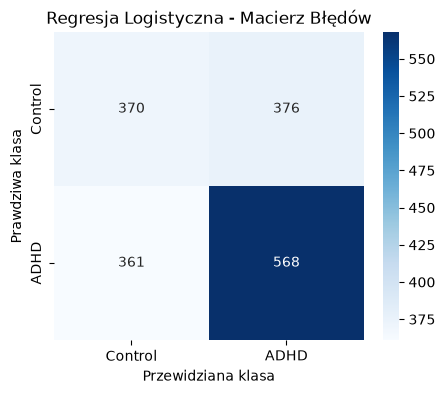

In [4]:
pipe_reg = get_pipeline('logreg')
param_grid_reg = {'classifier__C': [0.01, 0.1, 1, 10, 100]}
best_reg = run_grid_search(pipe_reg, param_grid_reg, X_train, y_train)

y_pred_reg = best_reg.predict(X_test)
print("Raport Klasyfikacji:")
print(classification_report(y_test, y_pred_reg))

plot_confusion_matrix(y_test, y_pred_reg, title="Regresja Logistyczna - Macierz Błędów")

Jak widać, wyniki regresji liniowej nie są zbyt dobre, wręcz tylko trochę lepsze od losowego klasyfikatora, co pokazuje, że dane zapewne nie są zbyt dobrze separowalne liniowo, szczególnie, że najlepszy wynik uzyskała najmniejsza regularyzacja, czyli tak jakby model próbował się jakos dostosować do tych skomplikowanych danych, ale i tak nie wyszło za bardzo.

## SVM
W SVMie celowałbym w kernel rbf, który przechodząc do większego wymiaru być może znajdzie dobry sposób na podzielenie danych i znalezienie granicy decyzyjnej.

Najlepsze hiperparametry: {'classifier__C': 0.1, 'classifier__kernel': 'rbf'}
Najlepszy wynik walidacji (roc_auc): 0.6587
Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.59      0.41      0.48       746
           1       0.62      0.77      0.69       929

    accuracy                           0.61      1675
   macro avg       0.61      0.59      0.59      1675
weighted avg       0.61      0.61      0.60      1675



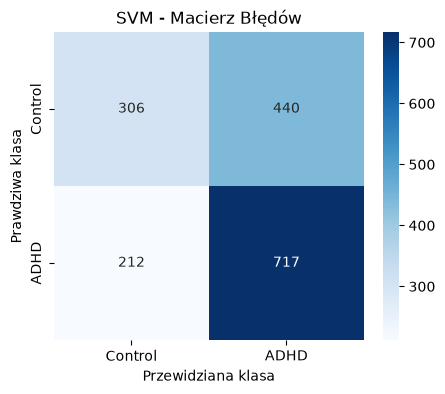

In [5]:
pipe_svm = get_pipeline('svm')
param_grid_svm = {'classifier__kernel': ['linear', 'rbf'], 'classifier__C': [0.1, 1, 10]}
best_svm = run_grid_search(pipe_svm, param_grid_svm, X_train, y_train)

y_pred_svm = best_svm.predict(X_test)
print("Raport Klasyfikacji:")
print(classification_report(y_test, y_pred_svm))

plot_confusion_matrix(y_test, y_pred_svm, title="SVM - Macierz Błędów")

Faktycznie najlepszym zestawem okazał się kernel rbf, z dużą regularyzacją (karaliśmy mocno duże wagi, co znów wskazuje, że dane są zaszumione i lepsze wyniki uzyskujemy dla większej generalizacji). Recall na poziomie prawie 0,8 to już naprawdę nieźle. Co prawda, skierowaliśmy aż 440 zdrowych osób na dodatkowe badania, ale w medycynie lepiej zrobić tak, niż mieć większe precision.

## Random Forest
Teraz czas na modele zespołowe; najpierw las losowy. Jest to komitet N drzew decyzyjnych, każde dostaje trochę inny zestaw cech i pacjentów, zazwyczaj najlepsze wyniki dostajemy, gdy dajemy im się rozrastać bez ograniczeń - każde drzewo może wykryć jakieś inne zależności, często są przeuczone ale generalizacja następuje przez głosowanie. Grid Search sprawdzi ilość drzew w lesie, maksymalną głębokość oraz minimalną ilość przykładów do podziału węzła 

Najlepsze hiperparametry: {'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Najlepszy wynik walidacji (roc_auc): 0.6875
Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.53      0.41      0.46       746
           1       0.60      0.71      0.65       929

    accuracy                           0.57      1675
   macro avg       0.56      0.56      0.55      1675
weighted avg       0.57      0.57      0.56      1675



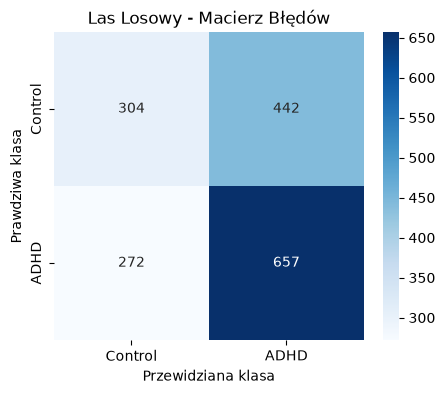

In [9]:
pipe_rf = get_pipeline('rf')
param_grid_rf = {'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, None], 'classifier__min_samples_split': [2, 5, 10]}
best_rf = run_grid_search(pipe_rf, param_grid_rf, X_train, y_train)

y_pred_rf = best_rf.predict(X_test)
print("Raport Klasyfikacji:")
print(classification_report(y_test, y_pred_rf))

plot_confusion_matrix(y_test, y_pred_rf, title="Las Losowy - Macierz Błędów")

Najlepsze wyniki dostaliśmy faktycznie dla lasu, który mógł się rozrastać do woli, dla 200 drzew, ale mimo tego drzewa aż tak się zapewne nie przeuczały, bo potrzeba było co najmniej 5 pacjentów do podziału, czyli liście nie kończyły się na pojedynczych przykładach; drzewo nie dostosowywało się do pojedynczych, zaszumionych sygnałów. Tu mamy właściwie najlepsze AUC na zbiorze walidacyjnym, prawie 0,69, czyli najlepszy trade-off, obniżając w razie potrzeby próg decyzyjny możemy zwiększyć recall nie zwiększając aż tak false positive'ów.

Na koniec Adaptive Boosting. Używa on drzew głębokości 1 i działa sekwencyjnie - każde kolejne drzewo skupia się na poprawianiu błędów poprzedniego. Tutaj przetestujemy ilość pieńków i learning rate.

Najlepsze hiperparametry: {'classifier__learning_rate': 0.1, 'classifier__n_estimators': 100}
Najlepszy wynik walidacji (roc_auc): 0.6539
Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.56      0.27      0.36       746
           1       0.58      0.83      0.69       929

    accuracy                           0.58      1675
   macro avg       0.57      0.55      0.52      1675
weighted avg       0.57      0.58      0.54      1675



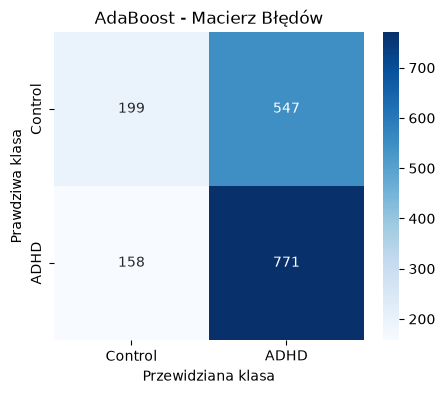

In [14]:
pipe_ada = get_pipeline('ada')
param_grid_ada = {'classifier__n_estimators': [50, 100, 200],
    'classifier__learning_rate': [0.01, 0.1, 1.0] }
best_ada = run_grid_search(pipe_ada, param_grid_ada, X_train, y_train)

y_pred_ada = best_ada.predict(X_test)
print("Raport Klasyfikacji:")
print(classification_report(y_test, y_pred_ada))

plot_confusion_matrix(y_test, y_pred_ada, title="AdaBoost - Macierz Błędów")

Adzie wyszedł najlepszy recall, ale ma słabsze AUC i faktycznie widać też, że zakwalifikowała dużo więcej dzieci zdrowych jako chore. 

Uważam zatem, że wygrał Random Forest. Narysujemy dla niego krzywą ROC oraz zobaczymy, jakie cechy są najważniejsze dla tego modelu.

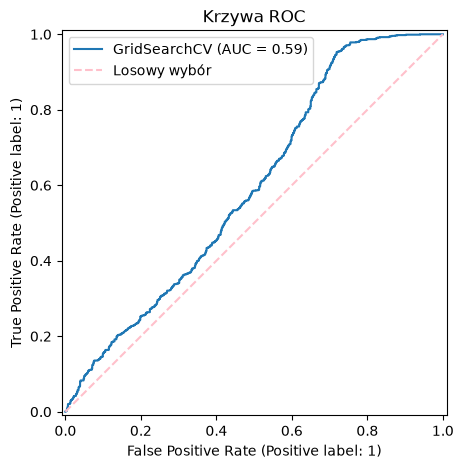

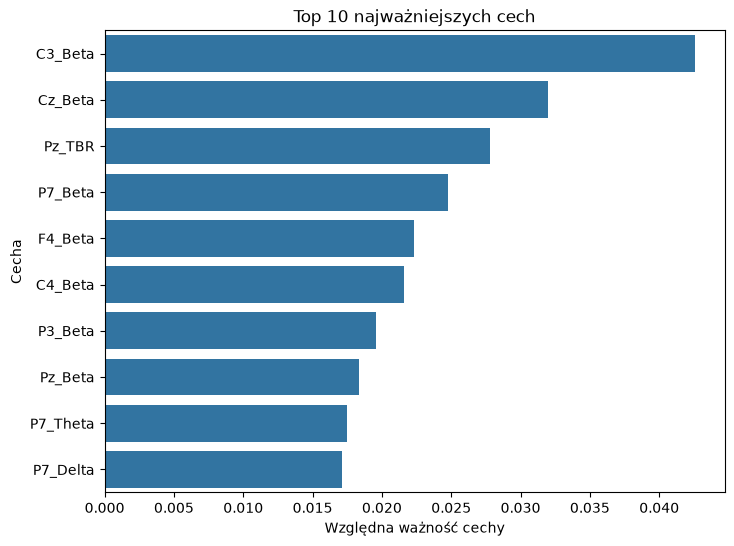

In [21]:
plot_roc(best_rf, X_test, y_test)
plot_importance(best_rf.best_estimator_, X_train.columns)

Jeśli chodzi o ważność cech, to jak widać, najważniejsze okazały się sygnały fal Beta, a także wskaźnik Beta/Theta, czyli dokładnie to co opisałem podczas analizy danych. Co do AUC dla naszego najlepszego modelu, to na zbiorze testowym osiągnęło zauważalnie gorszy wynik niż na walidacyjnym podczas Grid Searcha, ale potwierdza to na pewno, że nie mieliśmy wycieków danych podczas splitu zbioru. Ponadto jest to po prostu bardzo trudny zbiór, mocno zaszumiony faktem, że chore dzieci przyjmowały Ritalin.

Jak widzimy, klasyfikacja ADHD z EEG jest możliwa, ale na pewno bardzo nieliniowa. Dzięki temu, że wybieraliśmy model po AUC, wybraliśmy model, który faktycznie szuka wzorców, a nie przypisuje każdemu chorobę. 